In [2]:
pip install pandas numpy seaborn matplotlib openpyxl

You should consider upgrading via the '/Users/adil/Documents/TMP/hpv_research_visualisation-01/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as Patch
import seaborn as sns
sns.set_style("whitegrid")
import re


In [52]:
url = './HPV RESULT FINAL WITH EDITS (1).xlsx'
df = pd.read_excel(url, sheet_name='Sheet1')

In [3]:
df

,ID,Concentration,Result,Year,Age,Age_Cat,Genotype,Month,Month.1,Month-Year,Season
0,M3430,NaN,Negative,2.020000e+03,35,NaN,Not Detected,NaN,NaN,NaT,NaN
1,D19882,NaN,Negative,2.020000e+03,28,NaN,Not Detected,NaN,NaN,NaT,NaN
2,U011392,NaN,Negative,2.020000e+03,22,NaN,Not Detected,NaN,NaN,NaT,NaN
3,D27679,NaN,Negative,2.020000e+03,45,NaN,Not Detected,NaN,NaN,NaT,NaN
4,D30175,Medium,Positive,2.020000e+03,29,Adults (25–34 years),18/45,2020-02-02 00:00:00,2.0,2020-02-01,Winter
...,...,...,...,...,...,...,...,...,...,...,...
1815,A247101,LUCKY AKTER,36,8.801886e+12,Detected 16/31,NaN,14/12/24,NaN,NaN,NaT,NaN
1816,3 NEG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN
1817,M-1033536,MRS. ISRAT JAHAN,34,8.801719e+12,Detected 16/31,NaN,17/12/24,NaN,NaN,NaT,NaN
1818,13 NEG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN


In [4]:
grouped_df = df.groupby(['Year','Result']).size().unstack(fill_value=0)
grouped_df_xyz = grouped_df[['Positive','Negative']]
grouped_df_xyz.index
grouped_df_xyz
if 2024 in grouped_df_xyz:
    grouped_df_xyz.loc["Positive"] = 29
    grouped_df_xyz.loc["Negative"] = 587
grouped_df_xyz['positive_percentage (%)'] = ((grouped_df_xyz['Positive'] / (grouped_df_xyz['Positive'] + grouped_df_xyz['Negative'])) * 100).round(2)
grouped_df_xyz
grouped_df_xyz.to_csv("grouped_df_xyz.csv")
grouped_df = grouped_df_xyz
print(grouped_df)

Result        Positive  Negative  positive_percentage (%)
Year                                                     
2.020000e+03         1        39                     2.50
2.021000e+03         6       273                     2.15
2.022000e+03        19       494                     3.70
2.023000e+03        27       520                     4.94
2.024000e+03        20       404                     4.72
8.801685e+12         0         0                      NaN
8.801710e+12         0         0                      NaN
8.801711e+12         0         0                      NaN
8.801719e+12         0         0                      NaN
8.801719e+12         0         0                      NaN
8.801730e+12         0         0                      NaN
8.801760e+12         0         0                      NaN
8.801886e+12         0         0                      NaN


/var/folders/sz/r6t_6pq9165dybz5513mdzz40000gn/T/ipykernel_8708/2250204755.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  grouped_df_xyz['positive_percentage (%)'] = ((grouped_df_xyz['Positive'] / (grouped_df_xyz['Positive'] + grouped_df_xyz['Negative'])) * 100).round(2)


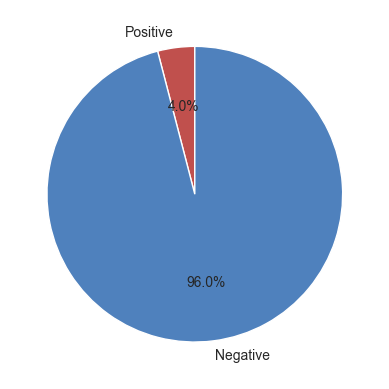

In [42]:
positive = grouped_df_xyz["Positive"].sum()
negative = grouped_df_xyz["Negative"].sum()
positive_and_negative = positive + negative
positive_percentage = (positive / positive_and_negative) * 100
negative_percentage = (negative / positive_and_negative) * 100 

y = np.array([positive_percentage, negative_percentage])
mylabels = ["Positive", "Negative"]

plt.pie(y, labels = mylabels,autopct="%1.1f%%", startangle = 90, colors = [ '#C0504D','#4F81BD'])
plt.show() 

In [6]:
# Assuming df is your dataframe
grouped_df = df.groupby(['Year', 'Result']).size().unstack(fill_value=0)

# Rename columns for better readability
# COPIED FROM AI
grouped_df = grouped_df.reindex(columns=['Negative','Positive']).fillna(0)
grouped_df.columns = ['Negative', 'Positive']

# Modify values correctly (if Year 2024 exists)
if 2024 in grouped_df.index:
    grouped_df.loc[2024, 'Positive'] = 29
    grouped_df.loc[2024, 'Negative'] = 587

# Recalculate positive percentage
grouped_df['positive_percentage (%)'] = ((grouped_df['Positive'] / (grouped_df['Positive'] + grouped_df['Negative'])) * 100).round(2)

grouped_df


# Display final dataframe
grouped_df

# save grouped_df as csv
grouped_df.to_csv('grouped_df.csv')
print(grouped_df)

              Negative  Positive  positive_percentage (%)
Year                                                     
2.020000e+03        39         1                     2.50
2.021000e+03       273         6                     2.15
2.022000e+03       494        19                     3.70
2.023000e+03       520        27                     4.94
2.024000e+03       587        29                     4.71
8.801685e+12         0         0                      NaN
8.801710e+12         0         0                      NaN
8.801711e+12         0         0                      NaN
8.801719e+12         0         0                      NaN
8.801719e+12         0         0                      NaN
8.801730e+12         0         0                      NaN
8.801760e+12         0         0                      NaN
8.801886e+12         0         0                      NaN


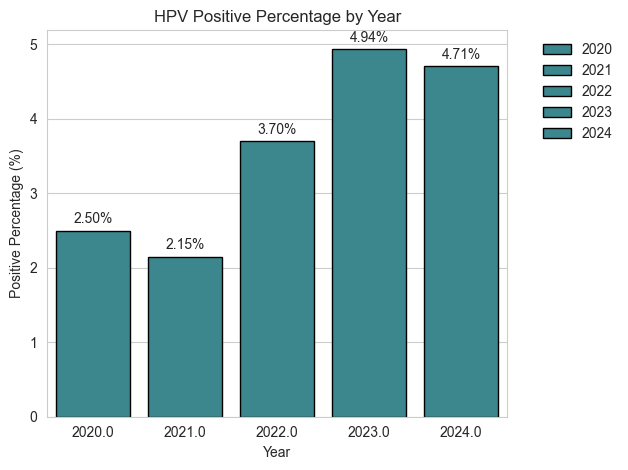

In [43]:
grouped_df = grouped_df.query('Year < 2030')

ax = sns.barplot(x=grouped_df.index, y='positive_percentage (%)', data=grouped_df, color='#2F929A', edgecolor='black')
plt.xticks(rotation=0)

plt.title('HPV Positive Percentage by Year')
plt.xlabel('Year')
plt.ylabel('Positive Percentage (%)')

# Add value labels directly on top of bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', fontsize=10, padding=3)
    

plt.legend(handles=ax.patches,labels=[str(year).replace(".0","") for year in grouped_df.index], frameon=False, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig("HPV_positive_percent_graph.png", dpi=300, bbox_inches='tight')

plt.show()

In [8]:
df

,ID,Concentration,Result,Year,Age,Age_Cat,Genotype,Month,Month.1,Month-Year,Season
0,M3430,NaN,Negative,2.020000e+03,35,NaN,Not Detected,NaN,NaN,NaT,NaN
1,D19882,NaN,Negative,2.020000e+03,28,NaN,Not Detected,NaN,NaN,NaT,NaN
2,U011392,NaN,Negative,2.020000e+03,22,NaN,Not Detected,NaN,NaN,NaT,NaN
3,D27679,NaN,Negative,2.020000e+03,45,NaN,Not Detected,NaN,NaN,NaT,NaN
4,D30175,Medium,Positive,2.020000e+03,29,Adults (25–34 years),18/45,2020-02-02 00:00:00,2.0,2020-02-01,Winter
...,...,...,...,...,...,...,...,...,...,...,...
1815,A247101,LUCKY AKTER,36,8.801886e+12,Detected 16/31,NaN,14/12/24,NaN,NaN,NaT,NaN
1816,3 NEG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN
1817,M-1033536,MRS. ISRAT JAHAN,34,8.801719e+12,Detected 16/31,NaN,17/12/24,NaN,NaN,NaT,NaN
1818,13 NEG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN


In [9]:
# Create a copy of the dataframe to avoid modifying the original
age_group = df[['Age_Cat', 'Result', 'Genotype']].copy()

# Function to clean Genotype values
def refine_genotype(genotype):
    try:
        if pd.isna(genotype):  # Keep NaN values unchanged
            return None
        elif "detected other" in str(genotype).lower() or "other" in str(genotype).lower():
            return "Other Genotype"  # Assign label for 'Detected other' cases
        else:
            match = re.search(r'[\d/]+', genotype)  # Extract numerical genotypes
            return match.group(0) if match else None
    except Exception as e:
        return None

# Apply the function to the Genotype column
age_group['Genotype'] = age_group['Genotype'].apply(refine_genotype)

# Display unique cleaned values
print(age_group['Genotype'].unique())  # Check the refined values


[None '18/45' '16/31' '16/18//45' '16/18' 'Other Genotype' '16' '16/18/45'
 '21/11/24' '14/12/24' '17/12/24' '22/12/24']


In [10]:
# Replace incorrect genotype value
age_group['Genotype'] = age_group['Genotype'].replace('16/18//45', '16/18/45')

# Verify if the replacement was successful
age_group['Genotype'].unique()  # Check unique values after replacement


age_group = age_group[age_group['Result'] == 'Positive']
age_group = age_group.groupby(['Age_Cat', 'Genotype']).size().unstack(fill_value=0)
age_group


Genotype,16,16/18,16/18/45,16/31,18/45,Other Genotype
Age_Cat,,,,,,
Adults (25–34 years),0,0,1,18,4,1
Middle Age (35–50 years),4,2,0,20,7,0
Older Adults (50+ years),1,0,0,4,0,1
Young Adults (15–24 years),0,0,0,7,3,0


['16', '16/18', '16/18/45', '16/31', '18/45', 'Other Genotype']


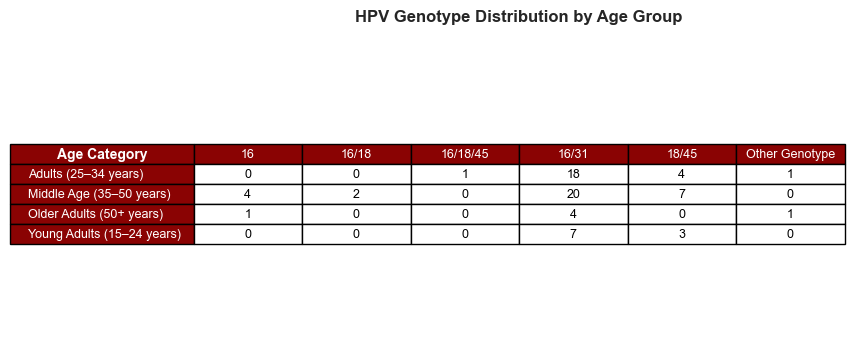

In [11]:
# Set figure size
fig, ax = plt.subplots(figsize=(7, 4))  # Increase size for better readability
ax.axis('off')
#table_df = age_group.reset_index()

# Hide axes
ax.xaxis.set_visible(False)
ax.yaxis.set_visible(False)
ax.set_frame_on(False)

# Modify column labels to include "Age Category" in the first column
col_labels = list(age_group.columns)  # Adding Age Category

# Create the table with colors
print(col_labels)
table = plt.table(cellText=age_group.values,
                  colLabels=col_labels,  # Add column label "Age Category"
                  rowLabels=age_group.index,
                  cellLoc='center',
                  loc='center',
                  colColours=["#8A0303"] * len(col_labels),  # Light blue headers
                  rowColours=["#8A0303"] * len(age_group.index))  # Light gray row labels

# Set font size
table.auto_set_font_size(False)
table.set_fontsize(9)

# Adjust column width to prevent label overlap
table.scale(1.2, 1.2)  # Scale table for better spacing

# Add title
plt.text(0.5, 1.1, "HPV Genotype Distribution by Age Group", fontsize=12, ha='center', va='top', fontweight='bold', transform=ax.transAxes)

# Save as PNG
plt.savefig("HPV_Age_Genotype_Table.png", dpi=300, bbox_inches="tight")


# Show the table (optional)
new_header = table.add_cell(0, -1, width=1.0, height=0.065,
                           text="Age Category",
                           loc='center', facecolor='#8A0303' )
new_header.set_text_props(weight='bold')


for cell in table.get_celld().values():
    cell.get_text().set_color('white')

for (row, col), cell in table.get_celld().items():
    # Data cells only (not header row and not row labels)
    if row > 0 and col >= 0:
        cell.get_text().set_color('black')


plt.show()


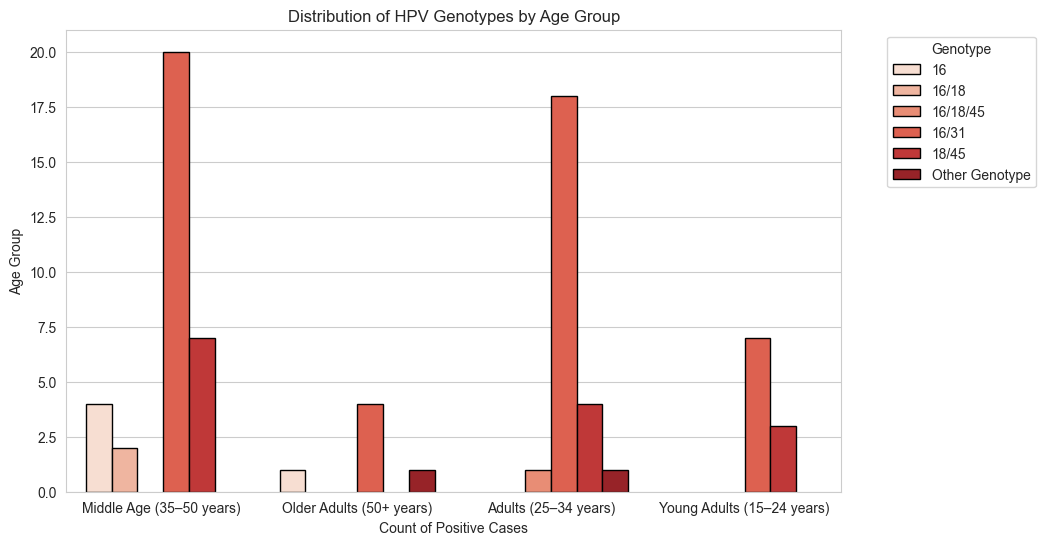

In [12]:
# Reset index and convert to long format
age_group_reset = age_group.reset_index()
long_df = age_group_reset.melt(id_vars=['Age_Cat'], var_name='Genotype', value_name='Count')

# Remove zero-count rows to eliminate gaps
long_df = long_df[long_df['Count'] > 0]

# Plot using Seaborn - switch x and y for horizontal bars
plt.figure(figsize=(10, 6))
ax = sns.barplot(y='Count', x='Age_Cat', hue='Genotype', data=long_df, palette='Reds', edgecolor='black')

# Improve readability
plt.xlabel('Count of Positive Cases')
plt.ylabel('Age Group')
plt.title('Distribution of HPV Genotypes by Age Group')

# Move legend outside the plot
plt.legend(title='Genotype', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.savefig("genotype_distribution.png", dpi=300, bbox_inches='tight')


# Show the plot
plt.show()

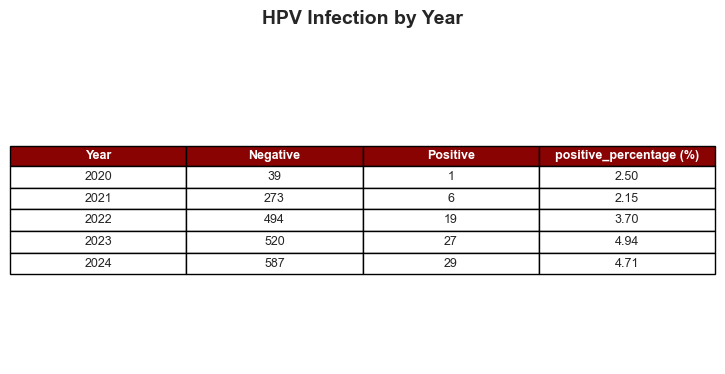

In [13]:
# Convert dataframe to include Year as a column and remove decimals
table_df = grouped_df.reset_index()
table_df['Year'] = table_df['Year'].astype(int)  # Convert Year to integer

# Format other numerical columns to remove unnecessary decimals
for col in ["Negative", "Positive", "positive_percentage (%)"]:
    table_df[col] = table_df[col].map(lambda x: f"{x:.2f}" if isinstance(x, float) else x)  # Keeps two decimal places

# Set figure size
fig, ax = plt.subplots(figsize=(7, 4))

# Hide axes
ax.xaxis.set_visible(False)
ax.yaxis.set_visible(False)
ax.set_frame_on(False)

# Define column labels
col_labels = table_df.columns

# Create the table
table = plt.table(cellText=table_df.values,
                  colLabels=col_labels,  # Explicitly set column labels
                  cellLoc='center',
                  loc='center',
                  colColours=["#8A0303"] * len(col_labels))  # Keep dark blue headers

# Set font size and improve readability
table.auto_set_font_size(False)
table.set_fontsize(9)

# Make header text white for better contrast
for (i, key) in enumerate(table._cells):
    cell = table._cells[key]
    if key[0] == 0:  # Header row
        cell.set_text_props(color="white", fontweight="bold")  # White text for visibility
        cell.set_height(0.05)  # Slightly taller headers

# Adjust column width to prevent overlap
table.scale(1.3, 1.3)

# Add a title
plt.text(0.5, 1.15, "HPV Infection by Year", fontsize=14, ha='center', va='top', fontweight='bold', transform=ax.transAxes)

# Save as PNG
plt.savefig("HPV_results_yearwise.png", dpi=300, bbox_inches="tight")

# Show the table (optional)
plt.show()

In [14]:
#files.download("HPV_results_yearwise.png")
#files.download('HPV_positive_percent_graph.png')
#files.download("HPV_Age_Genotype_Table.png")
#files.download("genotype_distribution.png")

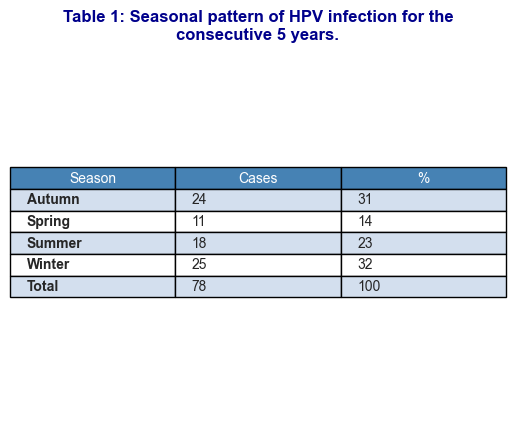

In [46]:
positive = df[df["Result"] == "Positive"]

data = positive.groupby("Season").size().reset_index(name="Cases")

total = data["Cases"].sum()
data["%"] = (data["Cases"] / total * 100).round().astype(int)

data.loc[len(data)] = ["Total", total, 100]

fig, ax = plt.subplots()
ax.axis("off")

table = ax.table(
    cellText=data.values,
    colLabels=data.columns,
    loc="center",
    cellLoc="left"
)

table.scale(1, 1.3)

for (row, col), cell in table.get_celld().items():
    if col == 0 and row > 0:
        cell.set_text_props(weight="bold")
    if row == 0:
        cell.set_facecolor("steelblue")
        cell.set_text_props(color="white")
    elif row % 2 != 0:
        cell.set_facecolor("#D3DFEE")

plt.title(
    'Table 1: Seasonal pattern of HPV infection for the\nconsecutive 5 years.',
    fontsize=12,
    fontweight='bold',
    color='darkblue'
)

plt.show()


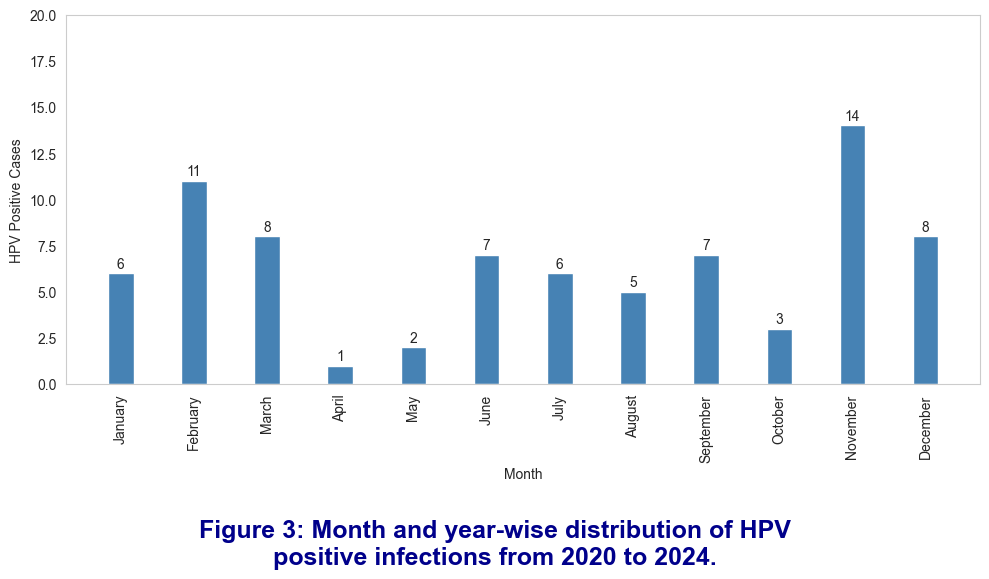

In [47]:
positive = df[df["Result"] == "Positive"]

monthly_cases = positive["Month.1"].value_counts().sort_index()

months = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

plt.figure(figsize=(10, 6))
plt.bar(months, monthly_cases.values, color="steelblue", width=0.35)
plt.xlabel("Month")
plt.ylabel("HPV Positive Cases")
plt.xticks(rotation=90)

for i in range(12):
    plt.text(i, monthly_cases.values[i] + 0.3,
             monthly_cases.values[i], ha="center")

plt.grid(False)
plt.ylim(0, 20)

plt.tight_layout()

plt.figtext(
    0.5, 0.05,
    "Figure 3: Month and year-wise distribution of HPV\npositive infections from 2020 to 2024.",
    ha="center",
    fontsize=18,
    fontweight="bold",
    color="darkblue"
)

plt.subplots_adjust(bottom=0.35)

plt.show()

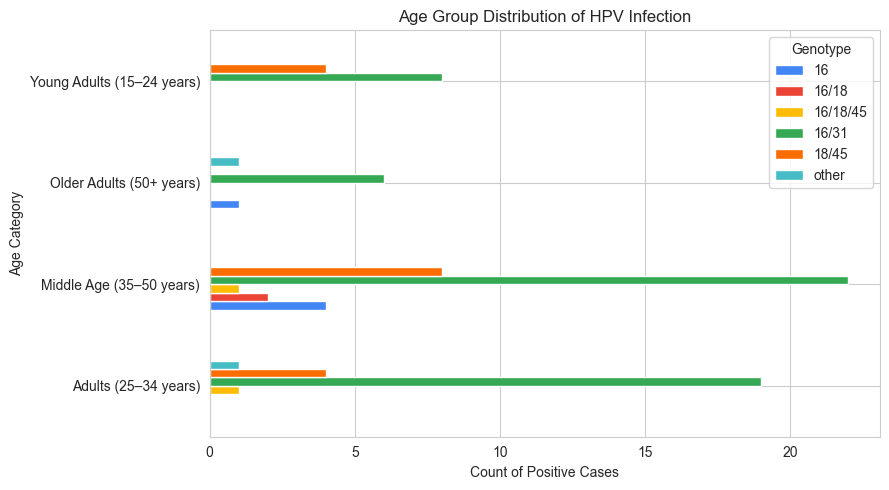

In [36]:

positive = df[df["Result"] == "Positive"].copy()

positive["Genotype"] = positive["Genotype"].str.lower().str.strip()
positive["Genotype"] = positive["Genotype"].str.replace("detected", "").str.strip()
positive["Genotype"] = positive["Genotype"].str.replace("//", "/")

positive.loc[positive["Genotype"].str.contains("other", na=False), "Genotype"] = "other"

data = pd.crosstab(positive["Age_Cat"], positive["Genotype"])

colors = {
    "16": "#4285F4",
    "16/18": "#EB4335",
    "16/18/45": "#FBBC03",
    "16/31": "#34A853",
    "18/45": "#FB6D01",
    "other": "#46BDC6"
}

data = data.reindex(columns=colors.keys(), fill_value=0)

data.plot(kind="barh", figsize=(9, 5),
          color=list(colors.values()))

plt.xlabel("Count of Positive Cases")
plt.ylabel("Age Category")
plt.title("Age Group Distribution of HPV Infection")
plt.legend(title="Genotype")
plt.tight_layout()
plt.show()


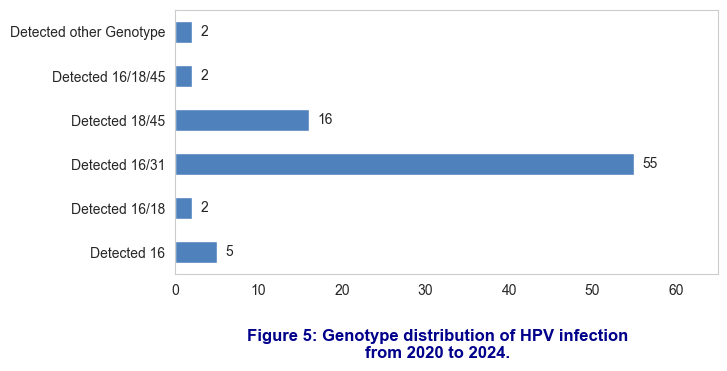

In [51]:

positive = df[df["Result"] == "Positive"].copy()

positive["Genotype"] = positive["Genotype"].str.lower().str.strip()
positive["Genotype"] = positive["Genotype"].str.replace("detected", "").str.strip()
positive["Genotype"] = positive["Genotype"].str.replace("//", "/")
positive.loc[positive["Genotype"].str.contains("other", na=False), "Genotype"] = "other"

data = positive["Genotype"].value_counts()

order = ["16", "16/18", "16/31", "18/45", "16/18/45", "other"]
data = data.reindex(order, fill_value=0)

data.index = ["Detected " + x for x in data.index]
data.index = data.index.str.replace("Detected other", "Detected other Genotype")

data.plot(kind="barh", color="#4F81BD", figsize=(7, 4))

plt.xlabel("")
plt.ylabel("")
plt.grid(False)
plt.xlim(0, max(data) + 10)

for i, value in enumerate(data):
    plt.text(value + 1, i, str(value), va="center")

plt.figtext(
    0.5, 0.01,
    "Figure 5: Genotype distribution of HPV infection\nfrom 2020 to 2024.",
    ha="center",
    fontsize=12,
    fontweight="bold",
    color="darkblue"
)

plt.subplots_adjust(bottom=0.22)
plt.show()
